### Install Dataset and Upload

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from medmnist import PneumoniaMNIST

DATA_DIR = Path("..") / "data"
DATA_DIR.mkdir(exist_ok=True)

train = PneumoniaMNIST(split="train", download=True, size=64, root=str(DATA_DIR))
val   = PneumoniaMNIST(split="val",   download=True, size=64, root=str(DATA_DIR))
test  = PneumoniaMNIST(split="test",  download=True, size=64, root=str(DATA_DIR))

print(train.info["label"])
print(DATA_DIR.resolve())

{'0': 'normal', '1': 'pneumonia'}
/Users/derentuzun/projects/dataset-detective/data


In [2]:
for name, ds in [("train", train), ("val", val), ("test", test)]:
    labels = ds.labels.flatten()
    counts = np.bincount(labels)
    print(f"{name:5s} | görüntü şekli: {ds.imgs.shape} | normal: {counts[0]} | pneumonia: {counts[1]}")

train | görüntü şekli: (4708, 64, 64) | normal: 1214 | pneumonia: 3494
val   | görüntü şekli: (524, 64, 64) | normal: 135 | pneumonia: 389
test  | görüntü şekli: (624, 64, 64) | normal: 234 | pneumonia: 390


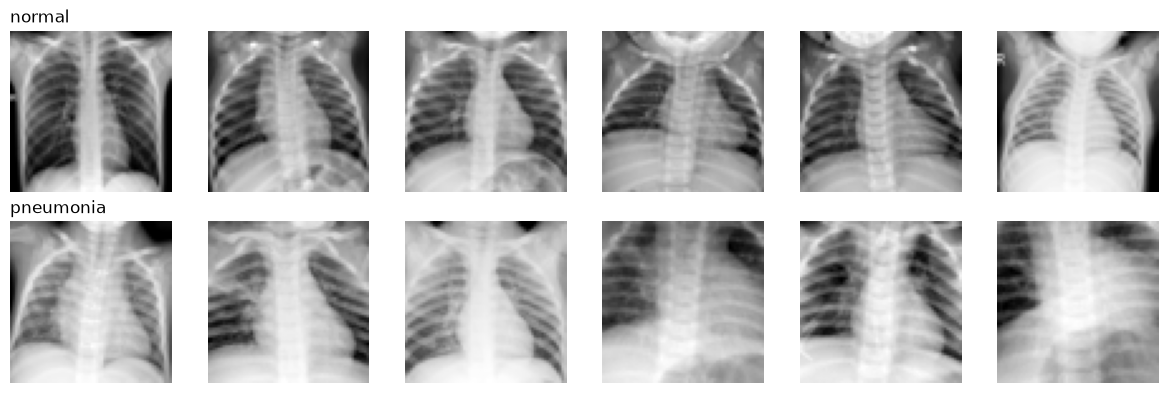

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for row, label in enumerate([0, 1]):
    idx = np.where(train.labels.flatten() == label)[0][:6]
    for col, i in enumerate(idx):
        axes[row, col].imshow(train.imgs[i], cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(train.info["label"][str(label)], loc="left")
plt.tight_layout()
plt.show()